<a href="https://colab.research.google.com/github/MomoHezz/Notas-de-Probabilidad/blob/main/probabilidad_frecuentista_t2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Ejercicio 1

Simula 10 000 lanzamientos de dos dados y estima la probabilidad de que la suma sea exactamente 5. Compara esa frecuencia con la probabilidad clásica que ya calculaste.

Para simular 10,000 lanzamientos y buscar la suma de 5, generamos dos números aleatorios del 1 al 6 en cada iteración. La probabilidad clásica es $1/9 \approx 0.1111$

In [ ]:
import random
import matplotlib.pyplot as plt

# Funcion que simula el lanzamiento de dos dados
def lanzar_dos_dados():
    # Sumamos dos numeros aleatorios del 1 al 6
    return random.randint(1, 6) + random.randint(1, 6)

# Numero total de lanzamientos
n = 10000
# Contador de sumas exactas de 5
conteo_suma_5 = 0
# Lista para guardar la frecuencia relativa
frecuencias = []

# Repetimos el experimento n veces
for i in range(1, n + 1):
    resultado = lanzar_dos_dados()
    # Verificamos si la suma es 5
    if resultado == 5:
        conteo_suma_5 += 1
    # Frecuencia relativa
    frecuencia = conteo_suma_5 / i
    frecuencias.append(frecuencia)

print("Número de lanzamientos:", n)
print("Probabilidad empírica de sumar 5:", frecuencia)

Número de lanzamientos: 10000
Probabilidad empírica de sumar 5: 0.1114


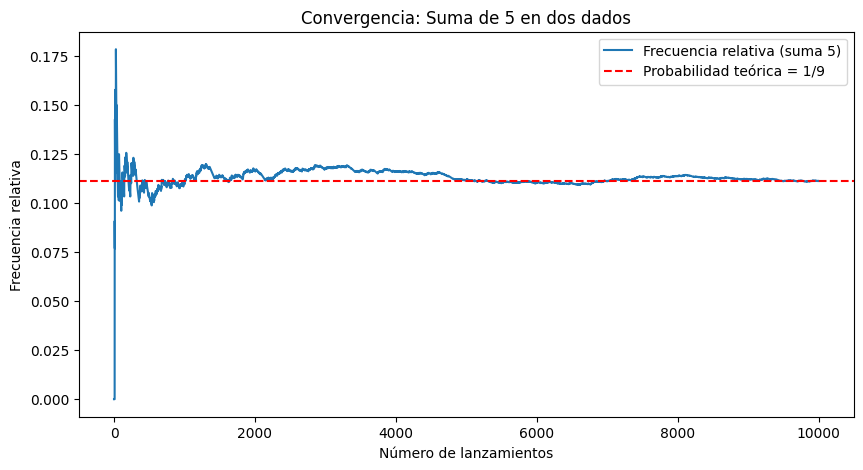

In [ ]:
plt.figure(figsize=(10,5))
plt.plot(frecuencias, label="Frecuencia relativa (suma 5)")
plt.axhline(1/9, color='red', linestyle="--", label="Probabilidad teórica = 1/9")
plt.xlabel("Número de lanzamientos")
plt.ylabel("Frecuencia relativa")
plt.title("Convergencia: Suma de 5 en dos dados")
plt.legend()
plt.show()

# Ejercicio 2
Simula 10 000 PIN de 4 dígitos, del 0 al 9, y estima la probabilidad de que ninguno se repita. Compara el resultado con la fracción de la parte clásica.

Simularemos 10,000 PINs de 4 dígitos del 0 al 9. Para que no se repitan, la longitud del PIN convertido a conjunto (set) debe ser igual a 4. La probabilidad clásica es $\frac{10 \times 9 \times 8 \times 7}{10^4} = 0.504$.

In [ ]:
import random
import matplotlib.pyplot as plt

def generar_pin(digitos):
    return [random.randint(0, 9) for _ in range(digitos)]

n = 10000
conteo_sin_repeticion = 0
frecuencias = []

for i in range(1, n + 1):
    pin = generar_pin(4)
    # Al convertir a set, si la longitud es 4 significa que no hay repetidos
    if len(set(pin)) == 4:
        conteo_sin_repeticion += 1
    frecuencia = conteo_sin_repeticion / i
    frecuencias.append(frecuencia)

print("Contraseñas simuladas:", n)
print("Frecuencia de PIN sin dígitos repetidos:", frecuencia)

Contraseñas simuladas: 10000
Frecuencia de PIN sin dígitos repetidos: 0.5107


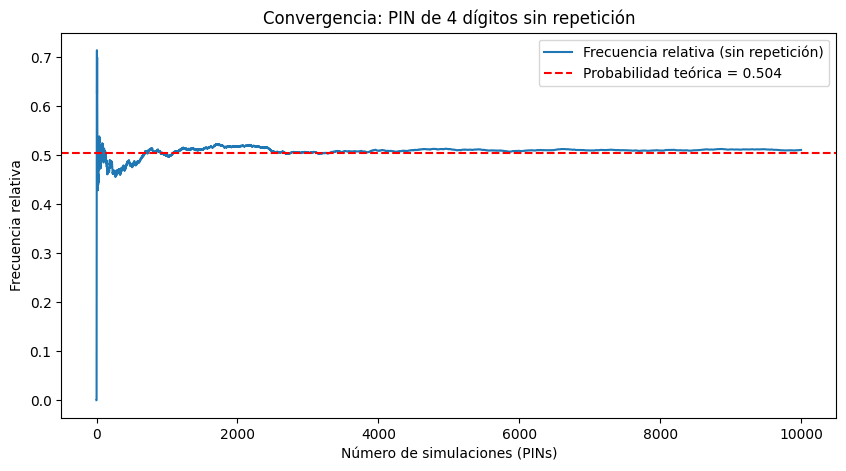

In [ ]:
plt.figure(figsize=(10,5))
plt.plot(frecuencias, label="Frecuencia relativa (sin repetición)")
plt.axhline(0.504, color='red', linestyle="--", label="Probabilidad teórica = 0.504")
plt.xlabel("Número de simulaciones (PINs)")
plt.ylabel("Frecuencia relativa")
plt.title("Convergencia: PIN de 4 dígitos sin repetición")
plt.legend()
plt.show()

# Ejercicio 3
Simula 20 000 lanzamientos de tres dados. Estima la frecuencia de la suma 9 y la de la suma 10. ¿Se nota, en la simulación, cuál de las dos sale más?

*Un ensayo son tres llamadas a lanzar_dado. Lleva dos conteos. La ventaja de una suma sobre la otra es pequeña: si en una corrida casi empatan, sube el número de lanzamientos y vuelve a correr.

Ejecutaremos 20,000 simulaciones para comparar ambas sumas. En la probabilidad clásica, la suma de 10 gana por un pequeño margen (27 contra 25 casos de 216).

In [ ]:
import random
import matplotlib.pyplot as plt

# Funcion que simula el lanzamiento de tres dados
def lanzar_tres_dados():
    return random.randint(1, 6) + random.randint(1, 6) + random.randint(1, 6)

n = 20000
conteo_9 = 0
conteo_10 = 0
frecuencias_9 = []
frecuencias_10 = []

for i in range(1, n + 1):
    resultado = lanzar_tres_dados()

    if resultado == 9:
        conteo_9 += 1
    elif resultado == 10:
        conteo_10 += 1

    frecuencias_9.append(conteo_9 / i)
    frecuencias_10.append(conteo_10 / i)

print("Número de lanzamientos:", n)
print("Probabilidad empírica de sumar 9:", frecuencias_9[-1])
print("Probabilidad empírica de sumar 10:", frecuencias_10[-1])

Número de lanzamientos: 20000
Probabilidad empírica de sumar 9: 0.1183
Probabilidad empírica de sumar 10: 0.12525


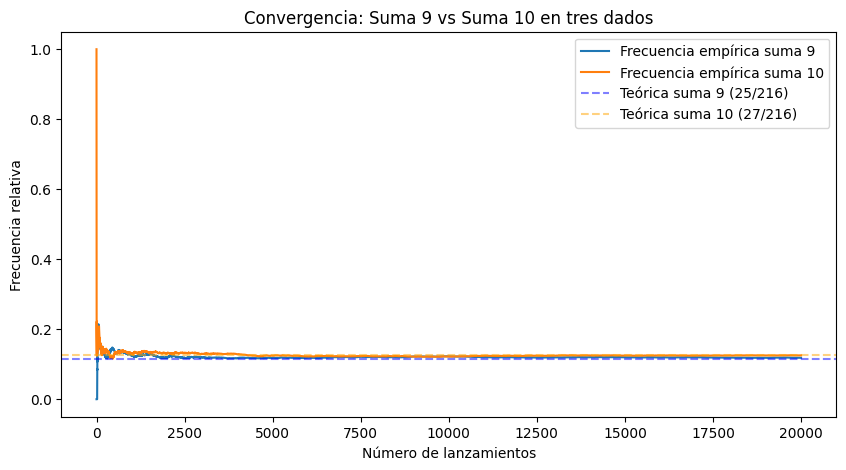

In [ ]:
plt.figure(figsize=(10,5))
plt.plot(frecuencias_9, label="Frecuencia empírica suma 9")
plt.plot(frecuencias_10, label="Frecuencia empírica suma 10")
plt.axhline(25/216, color='blue', linestyle="--", alpha=0.5, label="Teórica suma 9 (25/216)")
plt.axhline(27/216, color='orange', linestyle="--", alpha=0.5, label="Teórica suma 10 (27/216)")
plt.xlabel("Número de lanzamientos")
plt.ylabel("Frecuencia relativa")
plt.title("Convergencia: Suma 9 vs Suma 10 en tres dados")
plt.legend()
plt.show()

# Ejercicio 4
Basado en el Ejemplo 3, simula una urna con 3 bolas rojas y 2 azules. Realiza 2,000 extracciones (con reemplazo) y calcula la probabilidad de obtener una azul.

Se simula una urna con 3 bolas rojas y 2 azules. Extraemos un elemento al azar 2,000 veces. La probabilidad clásica es $2/5 = 0.4$.

In [ ]:
import random
import matplotlib.pyplot as plt

# Definimos una funcion que simula sacar una bola de la urna de 5 elementos
def sacar_bola():
    urna = ["roja", "roja", "roja", "azul", "azul"]
    return random.choice(urna)

n = 2000
conteo_azules = 0
frecuencias = []

for i in range(1, n + 1):
    resultado = sacar_bola()
    if resultado == "azul":
        conteo_azules += 1
    frecuencia = conteo_azules / i
    frecuencias.append(frecuencia)

print("Número de extracciones:", n)
print("Probabilidad empírica de obtener una bola azul:", frecuencia)

Número de extracciones: 2000
Probabilidad empírica de obtener una bola azul: 0.3935


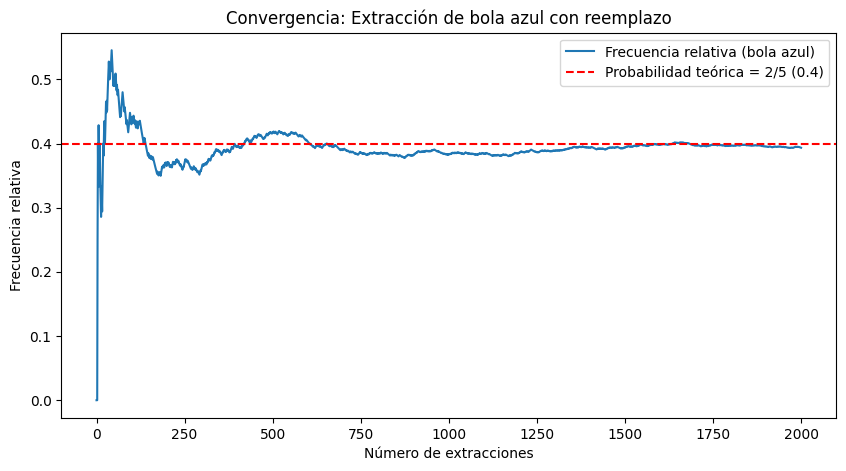

In [ ]:
plt.figure(figsize=(10,5))
plt.plot(frecuencias, label="Frecuencia relativa (bola azul)")
plt.axhline(0.4, color='red', linestyle="--", label="Probabilidad teórica = 2/5 (0.4)")
plt.xlabel("Número de extracciones")
plt.ylabel("Frecuencia relativa")
plt.title("Convergencia: Extracción de bola azul con reemplazo")
plt.legend()
plt.show()

# Ejercicio 5
Una serie son 20 volados. Estima, con 10 000 series, la probabilidad de que aparezcan 5 águilas seguidas en algún momento de la serie.

*Un ensayo no es un volado: son 20 llamadas a lanzar_moneda. Recorre esa serie y cuenta el ensayo si la racha de águilas llega a 5. La estimación es el número de series favorables entre 10 000. Aquí no hay una fracción simple de la parte clásica contra la cual dibujar la línea.

In [ ]:
import random
import matplotlib.pyplot as plt

def lanzar_moneda():
    return random.choice(["águila", "sol"])

# Funcion que evalua si hay una racha en la serie de volados
def simular_serie(volados):
    racha = 0
    for _ in range(volados):
        if lanzar_moneda() == "águila":
            racha += 1
            if racha == 5:
                return True
        else:
            racha = 0
    return False

n = 10000
conteo_racha = 0
frecuencias = []

for i in range(1, n + 1):
    if simular_serie(20):
        conteo_racha += 1
    frecuencia = conteo_racha / i
    frecuencias.append(frecuencia)

print("Número de series simuladas:", n)
print("Probabilidad empírica de obtener 5 águilas seguidas:", frecuencia)

Número de series simuladas: 10000
Probabilidad empírica de obtener 5 águilas seguidas: 0.2498


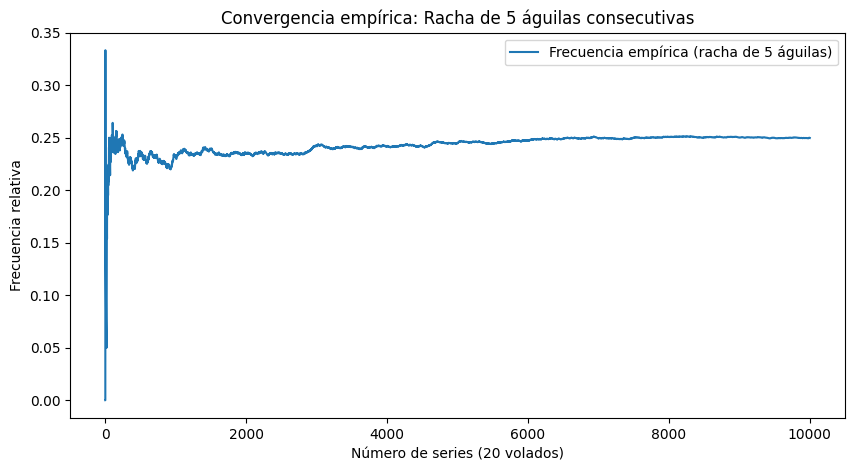

In [ ]:
plt.figure(figsize=(10,5))
plt.plot(frecuencias, label="Frecuencia empírica (racha de 5 águilas)")
plt.xlabel("Número de series (20 volados)")
plt.ylabel("Frecuencia relativa")
plt.title("Convergencia empírica: Racha de 5 águilas consecutivas")
plt.legend()
plt.show()

# Ejercicio 6 — Bonus
Los clientes llegan a una tienda de forma aleatoria (entre 1 y 5 minutos). El cajero tarda entre 2 y 4 minutos en atender. Simula la llegada de 500 clientes y calcula la probabilidad de que un cliente tenga que esperar más de 10 minutos en la fila.

In [ ]:
import random
import matplotlib.pyplot as plt

n = 500 # Corresponde a los 500 clientes
conteo_espera_larga = 0
frecuencias = []

tiempo_actual_llegada = 0
tiempo_liberacion_cajero = 0

for i in range(1, n + 1):
    # random.uniform permite decimales continuos entre 1 y 5
    tiempo_actual_llegada += random.uniform(1, 5)

    if tiempo_liberacion_cajero > tiempo_actual_llegada:
        tiempo_espera = tiempo_liberacion_cajero - tiempo_actual_llegada
    else:
        tiempo_espera = 0
        tiempo_liberacion_cajero = tiempo_actual_llegada

    if tiempo_espera > 10:
        conteo_espera_larga += 1

    tiempo_liberacion_cajero += random.uniform(2, 4)

    frecuencia = conteo_espera_larga / i
    frecuencias.append(frecuencia)

print("Número de clientes en la fila:", n)
print("Probabilidad empírica de esperar más de 10 min:", frecuencia)

Número de clientes en la fila: 500
Probabilidad empírica de esperar más de 10 min: 0.194


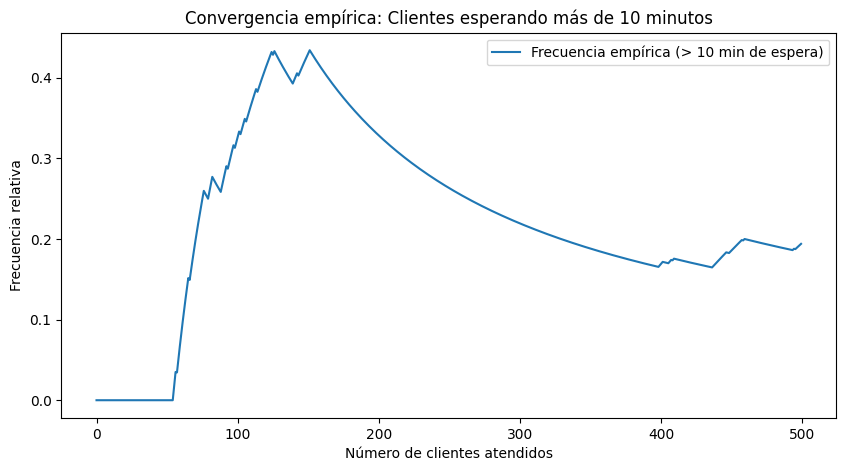

In [ ]:
plt.figure(figsize=(10,5))
plt.plot(frecuencias, label="Frecuencia empírica (> 10 min de espera)")
plt.xlabel("Número de clientes atendidos")
plt.ylabel("Frecuencia relativa")
plt.title("Convergencia empírica: Clientes esperando más de 10 minutos")
plt.legend()
plt.show()